In [4]:
import pandas as pd

df = pd.read_csv("sample_data.csv")

print("전체 데이터 크기:", df.shape)
display(df.head())

전체 데이터 크기: (300, 4)


,trust_score,english_level,ai_experience,decision
0,51,3,1,0
1,92,3,2,1
2,14,1,1,0
3,71,1,2,1
4,60,3,1,2


In [5]:
# 1. 결측치 확인
print("=== 결측치 확인 ===")
print(df.isnull().sum())

# 2. AI 피드백 수용 행동 분포
print("\n=== AI 피드백 수용 행동 분포 ===")
print("0 = 그대로 수용")
print("1 = 수정 후 사용")
print("2 = 거부")

print(df["decision"].value_counts().sort_index())

=== 결측치 확인 ===
trust_score      0
english_level    0
ai_experience    0
decision         0
dtype: int64

=== AI 피드백 수용 행동 분포 ===
0 = 그대로 수용
1 = 수정 후 사용
2 = 거부
decision
0     97
1    104
2     99
Name: count, dtype: int64


In [6]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

# 입력변수(X)와 예측변수(y)
X = df[["trust_score", "english_level", "ai_experience"]]
y = df["decision"]

# 학습용 80%, 평가용 20%
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 두 모델 비교
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42
    )
}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    print(f"\n{name}")
    print("Accuracy:", round(accuracy_score(y_test, pred), 3))
    print("F1-score:", round(f1_score(
        y_test, pred, average="macro"
    ), 3))


Logistic Regression
Accuracy: 0.35
F1-score: 0.268

Random Forest
Accuracy: 0.3
F1-score: 0.298


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

# 입력변수(X)와 목표변수(y)
X = df[["trust_score", "english_level", "ai_experience"]]
y = df["decision"]

# 학습 80%, 테스트 20%
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 머신러닝 모델 비교
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "F1-score": f1_score(y_test, pred, average="macro")
    })

results_df = pd.DataFrame(results)
display(results_df)

,Model,Accuracy,F1-score
0,Logistic Regression,0.35,0.268435
1,Random Forest,0.30,0.297791


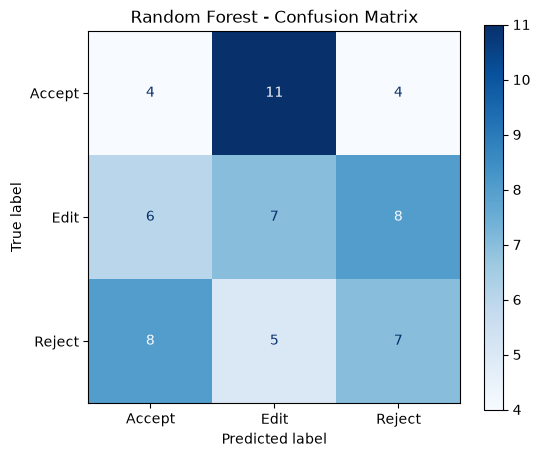

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Random Forest 모델의 예측 결과
rf_model = models["Random Forest"]
rf_pred = rf_model.predict(X_test)

# 혼동행렬 출력
fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_pred,
    labels=[0, 1, 2],
    display_labels=["Accept", "Edit", "Reject"],
    cmap="Blues",
    ax=ax
)

plt.title("Random Forest - Confusion Matrix")
plt.show()

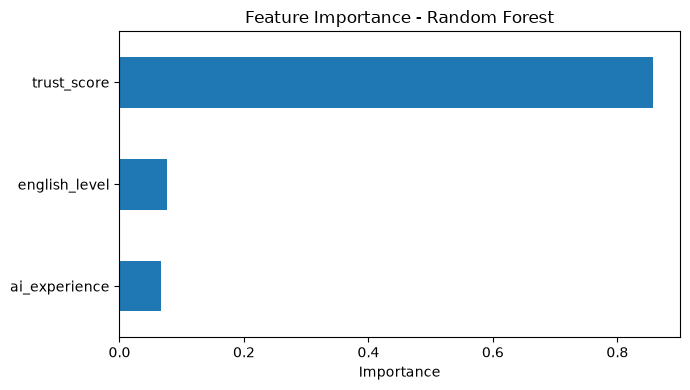

trust_score      0.857752
english_level    0.075848
ai_experience    0.066400
dtype: float64

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Random Forest의 변수 중요도 계산
importance = pd.Series(
    rf_model.feature_importances_,
    index=X.columns
).sort_values()

# 그래프 출력
fig, ax = plt.subplots(figsize=(7, 4))

importance.plot(
    kind="barh",
    ax=ax
)

ax.set_title("Feature Importance - Random Forest")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()

# 중요도 수치 출력
display(importance.sort_values(ascending=False))

In [ ]:
import pandas as pd

# 1. 데이터셋 불러오기
df = pd.read_csv("sample_data.csv")

# 2. 결측치 확인
print("결측치:", df.isnull().sum().sum(), "건")

# 3. AI 피드백 수용 행동별 빈도
print("수용:", (df["decision"] == 0).sum(), "건")
print("수정:", (df["decision"] == 1).sum(), "건")
print("거부:", (df["decision"] == 2).sum(), "건")

# 4. 전체 데이터 수
print("전체:", len(df), "건")

결측치: 0 건
수용: 97 건
수정: 104 건
거부: 99 건
전체: 300 건


In [9]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

# 데이터 불러오기
df = pd.read_csv("sample_data.csv")

X = df[["trust_score", "english_level", "ai_experience"]]
y = df["decision"]

# 학습용 80%, 평가용 20% 분할
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 두 모델 학습 및 비교
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Macro F1-score": f1_score(y_test, pred, average="macro")
    })

results_df = pd.DataFrame(results)

print("=== 머신러닝 모델 성능 비교 ===")
display(results_df.round(4))

=== 머신러닝 모델 성능 비교 ===


,Model,Accuracy,Macro F1-score
0,Logistic Regression,0.35,0.2684
1,Random Forest,0.30,0.2978
